<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# **Procesamiento de Lenguaje Natural**
## **Desafio, Traductor**

**Este desafío puede realizarse de manera individual o en pareja. En caso de realizarlo en pareja, solo uno de los integrantes deberá subir el desafío.**


Nombre(s):
* ...

### **Consigna**

* Replicar el modelo traductor desarrollado en clase (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### **Actividades opcionales**

* Incorporar embeddings preentrenados para ambos idiomas y evaluar su efecto sobre el rendimiento del modelo.
* Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).
* Implementar y entrenar una versión equivalente del modelo utilizando PyTorch, comparando los resultados con la implementación original.

## 1. Datos

Se utiliza el corpus **spa-eng** de pares de frases inglés–español (Tatoeba), el mismo
del notebook de clase, descargado desde el repositorio de datasets de TensorFlow. Cada
línea del archivo contiene una frase en inglés y su traducción al español separadas por
tabulación.

Antes de fijar la cantidad de muestras y la longitud máxima de secuencia se explora el
corpus, porque esas dos decisiones determinan tanto la dificultad de la tarea como el
costo de entrenamiento.

Una característica del dataset condiciona el muestreo: **los pares están ordenados por
longitud**, de las frases más cortas a las más largas. Tomar las primeras N líneas, por
lo tanto, no da una muestra representativa sino únicamente frases de dos o tres
palabras. Por eso se mezclan las líneas antes de recortar, con semilla fija para que el
subconjunto sea reproducible.

Ese mismo ordenamiento explica cómo se traduce el pedido de la consigna de trabajar con
secuencias más largas: al ampliar la cantidad de muestras respecto de las 10.000 del
ejemplo de clase, entran al conjunto frases progresivamente más extensas, lo que exige a
su vez elevar los límites `max_input_len` y `max_out_len`.

In [1]:
import os
import numpy as np

# Descarga del dataset (mismo que se ha usado enclase)
if not os.path.exists('spa-eng'):
    !curl -O https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip
    !unzip -q spa-eng.zip

with open('spa-eng/spa.txt', encoding='utf-8') as f:
    lineas = [l for l in f.read().split('\n') if '\t' in l]

print(f"Pares disponibles: {len(lineas):,}")
print("\nPrimeros ejemplos:")
for l in lineas[:3]:
    print("  ", l)
print("\nEjemplos del final (frases más largas):")
for l in lineas[-3:]:
    print("  ", l)

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 2576k  100 2576k    0     0  2800k      0 --:--:-- --:--:-- --:--:-- 2800k
Pares disponibles: 118,964

Primeros ejemplos:
   Go.	Ve.
   Go.	Vete.
   Go.	Vaya.

Ejemplos del final (frases más largas):
   A carbon footprint is the amount of carbon dioxide pollution that we produce as a result of our activities. Some people try to reduce their carbon footprint because they are concerned about climate change.	Una huella de carbono es la cantidad de contaminación de dióxido de carbono que producimos como producto de nuestras actividades. Algunas personas intentan reducir su huella de carbono porque están preocupados acerca del cambio climático.
   Since there are usually multiple websites on any given topic, I usually just click the back button when I arrive on any webpage that has pop-up advertising. I just go to the next page fou

inglés: media 6.3, mediana 6, p95 11, máx 47
español: media 6.1, mediana 6, p95 11, máx 49


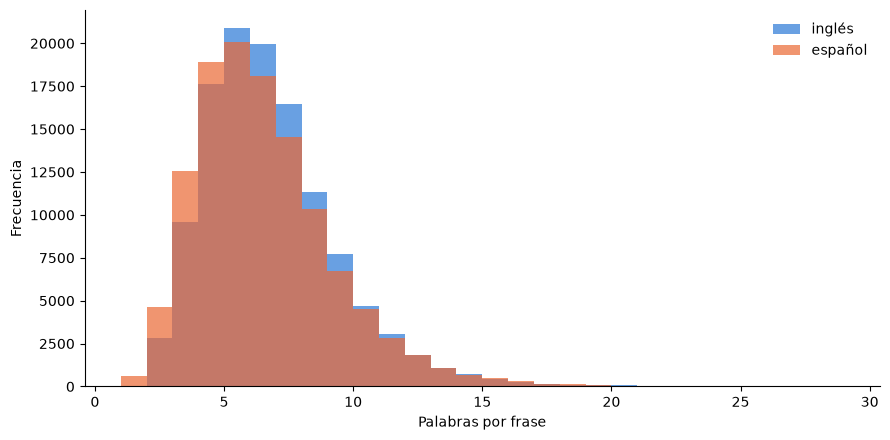

In [2]:
# Distribución de longitudes, en palabras
import matplotlib.pyplot as plt

pares = [l.split('\t')[:2] for l in lineas]
len_en = np.array([len(en.split()) for en, es in pares])
len_es = np.array([len(es.split()) for en, es in pares])

for nombre, largos in [("inglés", len_en), ("español", len_es)]:
    print(f"{nombre}: media {largos.mean():.1f}, mediana {np.median(largos):.0f}, "
          f"p95 {np.percentile(largos, 95):.0f}, máx {largos.max()}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(len_en, bins=range(1, 30), alpha=0.7, label='inglés', color='#2a78d6')
ax.hist(len_es, bins=range(1, 30), alpha=0.7, label='español', color='#eb6834')
ax.set_xlabel("Palabras por frase"); ax.set_ylabel("Frecuencia")
ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

### Escala del experimento

El corpus completo tiene 118.964 pares. La distribución de longitudes está concentrada
entre 4 y 10 palabras, con una cola delgada que llega a frases de más de 40 palabras.

Se toman **20.000 pares**, el doble que en el ejemplo de clase. Los límites de longitud
no se fijan a mano sino en el percentil 99 de la muestra: cubrir la cola completa
obligaría a un padding desproporcionado en el 99% de las frases, y el costo de cómputo
del decoder crece de forma lineal con la longitud máxima de la secuencia de salida. Las
frases que exceden ese límite se descartan.

In [3]:
MAX_NUM_SENTENCES = 20000

np.random.seed(40)
idx = np.random.permutation(len(lineas))[:MAX_NUM_SENTENCES]
muestra = [lineas[i].split('\t')[:2] for i in idx]

l_en = np.array([len(en.split()) for en, es in muestra])
l_es = np.array([len(es.split()) for en, es in muestra])

for nombre, l in [("inglés (entrada)", l_en), ("español (salida)", l_es)]:
    print(f"{nombre}: mediana {np.median(l):.0f} | p95 {np.percentile(l,95):.0f} | "
          f"p99 {np.percentile(l,99):.0f} | máx {l.max()}")

# Límites en el percentil 99 (+2 en la salida por los tokens <sos> y <eos>)
max_input_len = int(np.percentile(l_en, 99))
max_out_len = int(np.percentile(l_es, 99)) + 2

cobertura = np.mean((l_en <= max_input_len) & (l_es <= max_out_len - 2))
print(f"\nmax_input_len = {max_input_len}, max_out_len = {max_out_len}")
print(f"Pares que quedan dentro de los límites: {cobertura*100:.1f}%")

inglés (entrada): mediana 6 | p95 11 | p99 15 | máx 34
español (salida): mediana 6 | p95 11 | p99 15 | máx 42

max_input_len = 15, max_out_len = 17
Pares que quedan dentro de los límites: 99.1%
